# 01 - MSFT: data, features, baselines

Prototype the whole pipeline here, then move finished code into `src/stockpred/`.
Rule: every number that ends up on the resume must come from output in this notebook
or from `outputs/metrics.csv`.

**Question:** can simple models predict MSFT's next-day direction better than trivial baselines,
after transaction costs?

In [19]:
# Imports and settings.
# Needed: numpy, pandas, yfinance, matplotlib, scikit-learn, xgboost.
# Set a global random seed so reruns match.

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
import pandas_ta_classic as ta


## 1. Data

- Stock: MSFT. Reasons: liquid, long history, calmer than NVDA/TSLA, and different from the
  AAPL used in the KPI Anomaly Detection project. Note the survivorship bias (a hindsight pick).
- Download daily bars from 2010-01-01 with adjusted prices.
- Flatten yfinance's MultiIndex columns if present.
- Inspect: `.info()`, date range, missing days, NaNs, zero-volume days.
- Plot the close price. Any split-sized jumps mean the data is unadjusted.

In [20]:
# Download MSFT here
from tarfile import data_filter


stock = yf.Ticker("MSFT")

df = stock.history(start="2010-01-01")

df.head(10)

/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed i

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2010-01-04 00:00:00-05:00,22.739170,23.095629,22.716890,22.984236,38409100,0.0,0.0
2010-01-05 00:00:00-05:00,22.909973,23.095629,22.754021,22.991661,49749600,0.0,0.0
2010-01-06 00:00:00-05:00,22.932258,23.080784,22.664914,22.850571,58182400,0.0,0.0
2010-01-07 00:00:00-05:00,22.746596,22.798581,22.419842,22.612925,50559700,0.0,0.0
2010-01-08 00:00:00-05:00,22.486676,22.932250,22.456971,22.768873,51197400,0.0,0.0
2010-01-11 00:00:00-05:00,22.806004,22.843136,22.367857,22.479250,68754700,0.0,0.0
2010-01-12 00:00:00-05:00,22.390137,22.575793,22.211907,22.330727,65912100,0.0,0.0
2010-01-13 00:00:00-05:00,22.471828,22.664910,22.286171,22.538664,51863500,0.0,0.0
2010-01-14 00:00:00-05:00,22.508955,23.095629,22.471825,22.991661,63228100,0.0,0.0


In [21]:
# Data quality checks here

print(df.shape)

print(df.isnull().sum())

print(df.duplicated().sum())

print(df.describe())

print(df.info())

print(df.columns)


(4231, 7)
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64
0
              Open         High          Low        Close        Volume  \
count  4231.000000  4231.000000  4231.000000  4231.000000  4.231000e+03   
mean    162.783166   164.340000   161.170898   162.821197  3.520552e+07   
std     154.541067   155.968548   153.050263   154.556890  2.046484e+07   
min      17.305129    17.477506    17.035322    17.245171  5.855900e+06   
25%      32.212490    32.710517    31.867418    32.494553  2.207020e+07   
50%      90.467820    91.279370    89.637842    90.661476  2.940580e+07   
75%     277.291949   279.899999   274.080444   277.240936  4.286580e+07   
max     549.795172   551.150024   543.059998   543.450012  3.193179e+08   

         Dividends  Stock Splits  
count  4231.000000        4231.0  
mean      0.007343           0.0  
std       0.064638           0.0  
min       0.000000           0.0 

## 2. Features and target

Rule: a feature on row t uses data up to the close of day t only.

- Daily returns from the adjusted close.
- Keep the feature set small (8 to 12). With ~4,000 rows, more features means more overfitting.
- Features: lagged returns (1, 2, 5, 10, 21), rolling volatility (5, 21, 63), RSI(14),
  volume z-score, distance from 50- and 200-day moving averages.
- Target: 1 if the next day's return > 0, else 0. Keep `next_return` separately for the backtest.
- Drop warm-up rows (200-day window) and the last row.
- Check the class balance of the target (expect about 53% up).

In [22]:
# Build features and target here

# daily returns
df['daily_return'] = df['Close'].pct_change()

# rolling volatility
df['rolling_volatility'] = df['daily_return'].rolling(window=21).std()

# RSI
df['rsi'] = ta.rsi(df['Close'], length=14)

# distance from 50-day moving average
df['50_day_ma'] = df['Close'].rolling(window=50).mean()
df['200_day_ma'] = df['Close'].rolling(window=200).mean()

# distance from 200-day moving average
df['distance_50ma'] = df['Close'] - df['50_day_ma']
df['distance_200ma'] = df['Close'] - df['200_day_ma']

# volume z-score
df['volume_zscore'] = (df['Volume'] - df['Volume'].mean()) / df['Volume'].std()

## 3. Leakage check

Alter prices after some date t and confirm that the features on rows <= t do not change.
Then confirm the target is the only column that looks forward. Write this as a function,
because it becomes the first pytest test.

In [ ]:
# Check Leakage
# Features on row t may use data up to the close of day t only. Only the labels look forward.

SEED = 42
FEATURES = [
    'ret_1', 'ret_2', 'ret_5', 'ret_10', 'ret_21',
    'vol_5', 'vol_21', 'vol_63',
    'rsi_14', 'volume_z', 'dist_ma50', 'dist_ma200',
]

def build_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Build features, next_return and target from raw OHLCV bars."""
    close = raw['Close']
    volume = raw['Volume']
    daily_return = close.pct_change()

    out = pd.DataFrame(index=raw.index)
    for lag in (1, 2, 5, 10, 21):
        out[f'ret_{lag}'] = close.pct_change(lag)
    for window in (5, 21, 63):
        out[f'vol_{window}'] = daily_return.rolling(window).std()
    out['rsi_14'] = ta.rsi(close, length=14)
    # trailing z-score: full-sample mean/std would leak future volume into past rows
    volume_z = (volume - volume.rolling(63).mean()) / volume.rolling(63).std()
    out['volume_z'] = volume_z.replace([np.inf, -np.inf], np.nan)
    out['dist_ma50'] = close / close.rolling(50).mean() - 1
    out['dist_ma200'] = close / close.rolling(200).mean() - 1

    out['next_return'] = daily_return.shift(-1)
    out['target'] = (out['next_return'] > 0).astype(float)
    out.loc[out['next_return'].isna(), 'target'] = np.nan  # last row has no next day
    return out


def check_no_leakage(raw: pd.DataFrame, cutoff_pos: int = 2000, seed: int = SEED) -> None:
    """Scramble every bar after the cutoff; features on rows <= cutoff must not change."""
    rng = np.random.default_rng(seed)
    cutoff = raw.index[cutoff_pos]
    altered = raw[['Open', 'High', 'Low', 'Close', 'Volume']].astype(float)
    future = altered.index > cutoff
    altered.loc[future] = altered.loc[future].mul(rng.uniform(0.5, 2.0, future.sum()), axis=0)

    base = build_features(raw)
    new = build_features(altered)

    pd.testing.assert_frame_equal(base.loc[:cutoff, FEATURES], new.loc[:cutoff, FEATURES])
    # the check has power: the scrambled future must change the later features
    assert not base.loc[cutoff:, FEATURES].dropna().equals(new.loc[cutoff:, FEATURES].dropna())
    # the labels are the only look-ahead columns: they change on the cutoff row itself
    assert base.loc[cutoff, 'next_return'] != new.loc[cutoff, 'next_return']
    print(f'No leakage: {len(FEATURES)} features unchanged on rows <= {cutoff.date()}')


check_no_leakage(df)

# drop warm-up rows (200-day window) and the last row (no next day)
data = build_features(df).dropna(subset=FEATURES + ['next_return', 'target'])
data['target'] = data['target'].astype(int)
print(data.shape, data.index.min().date(), data.index.max().date())
print('Up fraction:', round(data['target'].mean(), 4))


No leakage: 12 features unchanged on rows <= 2017-12-12
(4031, 14) 2010-10-18 2026-10-27
Up fraction: 0.5239


## 4. Baselines

Compute on the same test periods the models will use:
- Always-up (accuracy ~ the up-fraction, AUC = 0.5)
- Previous-day direction
- Buy-and-hold, with the same cost model

These set the bar. Write down the numbers. Buy-and-hold on MSFT since 2010 is strong
(survivorship), so a long/flat strategy that is out of the market part of the time faces a
high bar on raw return. Compare risk-adjusted numbers (Sharpe, drawdown) too.

In [24]:
# Baselines here
from sklearn.metrics import roc_auc_score

COST = 0.0005  # 5 bps per position change
TRADING_DAYS = 252
INITIAL_TRAIN, TEST_SIZE, N_FOLDS, GAP = 756, 126, 8, 5  # rows: ~3y, ~6mo, blocks, ~1 week


def make_folds(n_rows: int) -> list[dict]:
    """Expanding-window folds. Train = rows [0, train_end), then GAP rows are skipped."""
    folds = []
    for k in range(N_FOLDS):
        test_start = INITIAL_TRAIN + GAP + k * TEST_SIZE
        test_end = test_start + TEST_SIZE
        assert test_end <= n_rows, 'not enough rows for the requested folds'
        folds.append({'fold': k, 'train_end': test_start - GAP,
                      'test_start': test_start, 'test_end': test_end})
    return folds


def strategy_net(score: pd.Series, test: pd.DataFrame) -> pd.Series:
    """Long if score > 0.5 else flat; the position set at close t earns next_return."""
    position = (score > 0.5).astype(int)
    turnover = position.diff().abs().fillna(position.abs())  # first entry also pays the cost
    return position * test['next_return'] - COST * turnover


def sharpe(returns: pd.Series) -> float:
    return returns.mean() / returns.std() * np.sqrt(TRADING_DAYS)


def max_drawdown(returns: pd.Series) -> float:
    equity = (1 + returns).cumprod()
    return (equity / equity.cummax() - 1).min()


def summarize(name: str, score: pd.Series, test: pd.DataFrame) -> dict:
    net = strategy_net(score, test)
    position = (score > 0.5).astype(int)
    return {
        'name': name,
        'accuracy': (position == test['target']).mean(),
        'auc': roc_auc_score(test['target'], score),
        'net_sharpe': sharpe(net),
        'max_drawdown': max_drawdown(net),
        'total_return': (1 + net).prod() - 1,
        'trades': int(position.diff().abs().fillna(position).sum()),
    }


folds = make_folds(len(data))
pooled_test = pd.concat([data.iloc[f['test_start']:f['test_end']] for f in folds])

baseline_scores = {
    'always_up (= buy and hold)': pd.Series(1.0, index=pooled_test.index),
    'previous_day_direction': (pooled_test['ret_1'] > 0).astype(float),
}
baselines = pd.DataFrame([summarize(name, score, pooled_test)
                          for name, score in baseline_scores.items()]).set_index('name')
print(f'Pooled test rows: {len(pooled_test)} '
      f'({pooled_test.index.min().date()} to {pooled_test.index.max().date()})')
baselines.round(4)


Pooled test rows: 1008 (2013-10-25 to 2017-10-25)


,accuracy,auc,net_sharpe,max_drawdown,total_return,trades
name,,,,,,
always_up (= buy and hold),0.5159,0.5000,1.1441,-0.1805,1.4485,1
previous_day_direction,0.4861,0.4856,0.3064,-0.2416,0.1543,518


## 5. Walk-forward prototype

- Hold out an initial ~3-year training period, then 8 consecutive test blocks of ~6 months.
  Expanding training window, split by date, small gap between train and test.
- Logistic regression (scaler fit on the train window only), then XGBoost (shallow, regularised).
- Per fold: AUC and accuracy. A fold has only ~125 rows, so per-fold numbers are noisy.
  Judge on the pooled out-of-sample predictions.
- Strategy: long if P(up) > 0.5, else flat. Subtract 5 bps on each position change.
- Metrics: net Sharpe (sqrt(252)), max drawdown, equity curve.
- Sanity checks: a shuffled-target model should score AUC ~ 0.5, and an oracle should score 1.0.
- Bootstrap a confidence interval for pooled AUC and Sharpe.

In [25]:
# Fold construction here
# `folds` is built in the Baselines cell so the baselines use the same test blocks.
fold_table = pd.DataFrame([{
    'fold': f['fold'],
    'train_start': data.index[0].date(),
    'train_end': data.index[f['train_end'] - 1].date(),
    'test_start': data.index[f['test_start']].date(),
    'test_end': data.index[f['test_end'] - 1].date(),
    'n_train': f['train_end'],
    'n_test': f['test_end'] - f['test_start'],
    'test_up_fraction': round(data['target'].iloc[f['test_start']:f['test_end']].mean(), 3),
} for f in folds])

for f in folds:
    assert f['train_end'] + GAP == f['test_start'], 'train must end GAP rows before test starts'
for prev, nxt in zip(folds, folds[1:]):
    assert prev['test_end'] == nxt['test_start'], 'test blocks must be consecutive'
fold_table


,fold,train_start,train_end,test_start,test_end,n_train,n_test,test_up_fraction
0,0,2010-10-18,2013-10-17,2013-10-25,2014-04-28,756,126,0.524
1,1,2010-10-18,2014-04-21,2014-04-29,2014-10-24,882,126,0.516
2,2,2010-10-18,2014-10-17,2014-10-27,2015-04-28,1008,126,0.476
3,3,2010-10-18,2015-04-21,2015-04-29,2015-10-26,1134,126,0.492
4,4,2010-10-18,2015-10-19,2015-10-27,2016-04-27,1260,126,0.508
5,5,2010-10-18,2016-04-20,2016-04-28,2016-10-25,1386,126,0.548
6,6,2010-10-18,2016-10-18,2016-10-26,2017-04-27,1512,126,0.492
7,7,2010-10-18,2017-04-20,2017-04-28,2017-10-25,1638,126,0.571


In [26]:
# Fit, predict, score here
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def make_models() -> dict:
    return {
        # the scaler lives inside the pipeline, so it is fit on the train window only
        'logreg': make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000)),
        'xgb': XGBClassifier(
            n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, min_child_weight=10, reg_lambda=5.0,
            eval_metric='logloss', n_jobs=1, random_state=SEED,
        ),
    }


rng = np.random.default_rng(SEED)
parts, fold_rows = [], []
for f in folds:
    train = data.iloc[:f['train_end']]
    test = data.iloc[f['test_start']:f['test_end']]
    part = pd.DataFrame(index=test.index)

    for name, model in make_models().items():
        model.fit(train[FEATURES], train['target'])
        part[name] = model.predict_proba(test[FEATURES])[:, 1]

    # sanity checks: shuffled train target should give AUC ~ 0.5; oracle should give 1.0
    for name, model in make_models().items():
        model.fit(train[FEATURES], rng.permutation(train['target'].values))
        part[f'{name}_shuffled'] = model.predict_proba(test[FEATURES])[:, 1]
    part['oracle'] = test['target'].astype(float)

    for column in part.columns:
        fold_rows.append({
            'fold': f['fold'], 'model': column,
            'auc': roc_auc_score(test['target'], part[column]),
            'accuracy': ((part[column] > 0.5).astype(int) == test['target']).mean(),
        })
    parts.append(part)

preds = pd.concat(parts)
assert preds.index.equals(pooled_test.index)

fold_scores = pd.DataFrame(fold_rows)
print('Per-fold AUC (noisy: ~126 rows per fold)')
print(fold_scores.pivot(index='fold', columns='model', values='auc').round(3))

pooled_scores = pd.DataFrame([{
    'model': column,
    'auc': roc_auc_score(pooled_test['target'], preds[column]),
    'accuracy': ((preds[column] > 0.5).astype(int) == pooled_test['target']).mean(),
} for column in preds.columns]).set_index('model')
print('\nPooled out-of-sample')
print(pooled_scores.round(4))
assert pooled_scores.loc['oracle', 'auc'] == 1.0, 'oracle must score 1.0'


/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/dhwanil/Desktop/ONGOI

Per-fold AUC (noisy: ~126 rows per fold)
model  logreg  logreg_shuffled  oracle    xgb  xgb_shuffled
fold                                                       
0       0.587            0.627     1.0  0.548         0.586
1       0.474            0.570     1.0  0.546         0.482
2       0.471            0.535     1.0  0.461         0.555
3       0.423            0.419     1.0  0.404         0.541
4       0.521            0.536     1.0  0.490         0.475
5       0.542            0.573     1.0  0.565         0.472
6       0.429            0.480     1.0  0.439         0.481
7       0.591            0.491     1.0  0.624         0.445

Pooled out-of-sample
                    auc  accuracy
model                            
logreg           0.4995    0.4931
xgb              0.5070    0.5109
logreg_shuffled  0.5176    0.5159
xgb_shuffled     0.5167    0.5119
oracle           1.0000    1.0000


/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/dhwanil/Desktop/ONGOING PROJECTS/stock market price prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/dhwanil/Desktop/ONGOI

Net of 5 bps per position change
                        accuracy     auc  net_sharpe  max_drawdown  \
name                                                                 
buy_and_hold              0.5159  0.5000      1.1441       -0.1805   
previous_day_direction    0.4861  0.4856      0.3064       -0.2416   
logreg                    0.4931  0.4995      1.1484       -0.1621   
xgb                       0.5109  0.5070      0.8410       -0.1528   

                        total_return  trades  
name                                          
buy_and_hold                  1.4485       1  
previous_day_direction        0.1543     518  
logreg                        0.7640     180  
xgb                           0.5641     315  


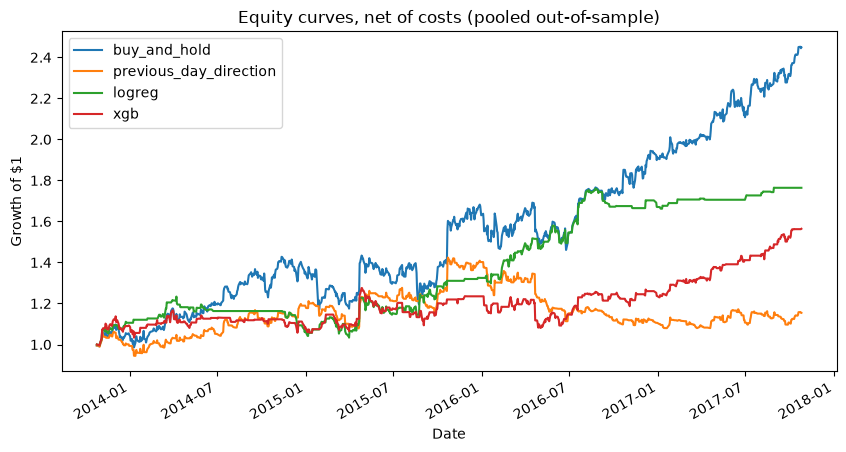

In [27]:
# Strategy returns, costs, equity curves here
from pathlib import Path

scores = {
    'buy_and_hold': baseline_scores['always_up (= buy and hold)'],
    'previous_day_direction': baseline_scores['previous_day_direction'],
    'logreg': preds['logreg'],
    'xgb': preds['xgb'],
}
metrics = pd.DataFrame([summarize(name, score, pooled_test)
                        for name, score in scores.items()]).set_index('name')
print('Net of 5 bps per position change')
print(metrics.round(4))

net_returns = {name: strategy_net(score, pooled_test) for name, score in scores.items()}

fig, ax = plt.subplots(figsize=(10, 5))
for name, net in net_returns.items():
    (1 + net).cumprod().plot(ax=ax, label=name)
ax.set_title('Equity curves, net of costs (pooled out-of-sample)')
ax.set_ylabel('Growth of $1')
ax.legend()
plt.show()

Path('../outputs').mkdir(exist_ok=True)
metrics.round(6).to_csv('../outputs/metrics.csv')


In [28]:
# Bootstrap confidence intervals here
# Moving-block bootstrap (21-day blocks) keeps the autocorrelation of returns.
N_BOOT, BLOCK = 1000, 21

boot_rng = np.random.default_rng(SEED)
n_rows = len(pooled_test)
target = pooled_test['target'].values
net_values = {name: net.values for name, net in net_returns.items()}


def block_sample(n: int) -> np.ndarray:
    n_blocks = int(np.ceil(n / BLOCK))
    starts = boot_rng.integers(0, n - BLOCK + 1, n_blocks)
    return (starts[:, None] + np.arange(BLOCK)).ravel()[:n]


def sharpe_values(values: np.ndarray) -> float:
    return values.mean() / values.std(ddof=1) * np.sqrt(TRADING_DAYS)


auc_draws = {name: [] for name in ('logreg', 'xgb')}
sharpe_draws = {name: [] for name in net_values}
for _ in range(N_BOOT):
    idx = block_sample(n_rows)
    for name in auc_draws:
        auc_draws[name].append(roc_auc_score(target[idx], preds[name].values[idx]))
    for name, values in net_values.items():
        sharpe_draws[name].append(sharpe_values(values[idx]))

rows = []
for name, draws in auc_draws.items():
    low, high = np.percentile(draws, [2.5, 97.5])
    rows.append({'metric': f'{name} pooled AUC', 'estimate': pooled_scores.loc[name, 'auc'],
                 'ci_low': low, 'ci_high': high, 'excludes_0.5': bool(low > 0.5 or high < 0.5)})
for name, draws in sharpe_draws.items():
    low, high = np.percentile(draws, [2.5, 97.5])
    rows.append({'metric': f'{name} net Sharpe', 'estimate': metrics.loc[name, 'net_sharpe'],
                 'ci_low': low, 'ci_high': high, 'excludes_0.5': np.nan})
for name in ('logreg', 'xgb'):
    diff = np.array(sharpe_draws[name]) - np.array(sharpe_draws['buy_and_hold'])
    low, high = np.percentile(diff, [2.5, 97.5])
    rows.append({'metric': f'{name} Sharpe minus buy-and-hold',
                 'estimate': metrics.loc[name, 'net_sharpe'] - metrics.loc['buy_and_hold', 'net_sharpe'],
                 'ci_low': low, 'ci_high': high, 'excludes_0.5': np.nan})

pd.DataFrame(rows).set_index('metric').round(4)


,estimate,ci_low,ci_high,excludes_0.5
metric,,,,
logreg pooled AUC,0.4995,0.4595,0.5406,False
xgb pooled AUC,0.5070,0.4658,0.5426,False
buy_and_hold net Sharpe,1.1441,0.2959,1.9345,NaN
previous_day_direction net Sharpe,0.3064,-0.6422,1.0544,NaN
logreg net Sharpe,1.1484,0.1716,1.9188,NaN
xgb net Sharpe,0.8410,-0.0843,1.5610,NaN
logreg Sharpe minus buy-and-hold,0.0042,-0.9174,0.8707,NaN
xgb Sharpe minus buy-and-hold,-0.3031,-1.0372,0.4190,NaN


## 6. Findings

Fill in after running. Cover:
- Did either model beat the baselines in pooled AUC? By how much, and does the confidence interval exclude 0.5?
- What happened to the edge after costs, and versus buy-and-hold?
- Which features mattered (feature importances here, SHAP later)?
- What are the limits? (one stock picked with hindsight, one cost assumption, daily bars only, small sample)

If the honest result is "barely better than the baseline", say that. It is a defensible resume story.